## Supervisor-Agent

![alt text](image-3.png)

In [12]:
%%capture --no-stderr
%pip install langgraph-supervisor
%pip install --quiet -U langchain_core langgraph langchain_openai

In [13]:
import os, getpass

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("OPENAI_API_KEY")

In [14]:
from langchain_openai import ChatOpenAI

from langgraph_supervisor import create_supervisor
#from langgraph.prebuilt import create_react_agent
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
#from langgraph.checkpoint.sqlite import SqliteSaver

# Set up memory
checkpointer = InMemorySaver() # short term memory (within thread)
store = InMemoryStore() # long term memory (across multiple threads)
#memory = SqliteSaver.from_file("langgraph_memory.sqlite") # persistent sqlite database
#memory = SqliteSaver.from_file(":memory:") # in-memory sqlite database

# Set up model
model = ChatOpenAI(model="gpt-4o")

# Create specialized agents

def add(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b

def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b

def web_search(query: str) -> str:
    """Search the web for information."""
    return (
        "Here are the headcounts for each of the FAANG companies in 2024:\n"
        "1. **Facebook (Meta)**: 67,317 employees.\n"
        "2. **Apple**: 164,000 employees.\n"
        "3. **Amazon**: 1,551,000 employees.\n"
        "4. **Netflix**: 14,000 employees.\n"
        "5. **Google (Alphabet)**: 181,269 employees."
    )

math_agent = create_agent(
    model=model,
    tools=[add, multiply],
    name="math_expert",
    system_prompt="You are a math expert. Always use one tool at a time."
)

research_agent = create_agent(
    model=model,
    tools=[web_search],
    name="research_expert",
    system_prompt="You are a world class researcher with access to web search. Do not do any math."
)

# Create supervisor workflow
workflow = create_supervisor(
    [research_agent, math_agent],
    model=model,
    prompt=(
        "You are a team supervisor managing a research expert and a math expert. "
        "For current events, use research_agent. "
        "For math problems, use math_agent."
    ),
    checkpointer=checkpointer,
)

config = {"configurable": {"thread_id": "6789"}}

# Compile and run
app = workflow.compile(checkpointer=checkpointer, store=store)

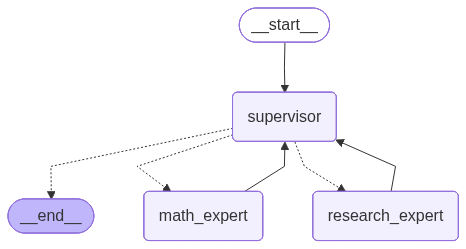

In [15]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [16]:
result = app.invoke({
        "messages": [
            {
            "role": "user",
            "content": "what's the combined headcount of the FAANG companies in 2024?"
            }
        ]
    },
    config=config
)

In [17]:
for m in result['messages']:
#for m in result['messages']: # Print last message only
    m.pretty_print()

================================ Human Message =================================

what's the combined headcount of the FAANG companies in 2024?
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_research_expert (call_LMjrAhqO7cgoXSU0JjQDmKmu)
 Call ID: call_LMjrAhqO7cgoXSU0JjQDmKmu
  Args:
================================= Tool Message =================================
Name: transfer_to_research_expert

Successfully transferred to research_expert
================================== Ai Message ==================================

Here are the headcounts for each of the FAANG companies in 2024:

1. **Facebook (Meta)**: 67,317 employees.
2. **Apple**: 164,000 employees.
3. **Amazon**: 1,551,000 employees.
4. **Netflix**: 14,000 employees.
5. **Google (Alphabet)**: 181,269 employees.

This gives a combined headcount of 1,977,586 employees for the FAANG companies in 2024.
================================== Ai Message ===

In [18]:
# Know the message history
result = app.invoke({
        "messages": [
            {
            "role": "user",
            "content": "what's number of employees in Meta?"
            }
        ]
    },
    config=config
)

In [19]:
for m in result['messages']:
#for m in result['messages']: # Print last message only
    m.pretty_print()

================================ Human Message =================================

what's the combined headcount of the FAANG companies in 2024?
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_research_expert (call_LMjrAhqO7cgoXSU0JjQDmKmu)
 Call ID: call_LMjrAhqO7cgoXSU0JjQDmKmu
  Args:
================================= Tool Message =================================
Name: transfer_to_research_expert

Successfully transferred to research_expert
================================== Ai Message ==================================

Here are the headcounts for each of the FAANG companies in 2024:

1. **Facebook (Meta)**: 67,317 employees.
2. **Apple**: 164,000 employees.
3. **Amazon**: 1,551,000 employees.
4. **Netflix**: 14,000 employees.
5. **Google (Alphabet)**: 181,269 employees.

This gives a combined headcount of 1,977,586 employees for the FAANG companies in 2024.
================================== Ai Message ===

## Last message only
![alt text](image-2.png)

## Take a look at checkpointing and state retrieval

In [20]:
# Retrieve the latest state
latest_state = app.get_state(config)
print(f"Latest state: {latest_state.values}")

# Retrieve the state history
state_history = app.get_state_history(config)
for i, snapshot in enumerate(state_history):
    print(f"Checkpoint {i}: {snapshot.values}")

Latest state: {'messages': [HumanMessage(content="what's the combined headcount of the FAANG companies in 2024?", additional_kwargs={}, response_metadata={}, id='5d5f79a3-f76b-431f-b6a9-c521975023c1'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 112, 'total_tokens': 126, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_cbf1785567', 'id': 'chatcmpl-CYuMGBXTkr1rU0vlZt2qDABP1oRPt', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, name='supervisor', id='lc_run--958a7d2b-d3c4-4979-8d34-b6d525ecf397-0', tool_calls=[{'name': 'transfer_to_research_expert', 'args': {}, 'id': 'call_LMjrAhqO7cgoXSU0JjQDmKmu', 'type': 'tool_call'}], usage

## Full history of messages

![alt text](image-1.png)

In [21]:
message_history_workflow = create_supervisor(
    [research_agent, math_agent],
    model=model,
    prompt=(
        "You are a team supervisor managing a research expert and a math expert. "
        "For current events, use research_agent. "
        "For math problems, use math_agent."
    ),
    output_mode='full_history'
    #output_mode='last_message' # Default
)

# Compile and run
message_history_app = message_history_workflow.compile()
message_history_result = message_history_app.invoke({
    "messages": [
        {
            "role": "user",
            "content": "what's the combined headcount of the FAANG companies in 2024?"
        }
    ]
})

In [22]:
for m in message_history_result['messages']:
#for m in result['messages']: # Print last message only
    m.pretty_print()

================================ Human Message =================================

what's the combined headcount of the FAANG companies in 2024?
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_research_expert (call_lrCLxI0ESZdOiRN1ZXWJwOVy)
 Call ID: call_lrCLxI0ESZdOiRN1ZXWJwOVy
  Args:
================================= Tool Message =================================
Name: transfer_to_research_expert

Successfully transferred to research_expert
================================== Ai Message ==================================
Tool Calls:
  web_search (call_MBgQPBj3PxknrAUEFqYrTDIp)
 Call ID: call_MBgQPBj3PxknrAUEFqYrTDIp
  Args:
    query: Facebook headcount 2024
  web_search (call_A7wwvnV6Yu2VgojYrXobMDzY)
 Call ID: call_A7wwvnV6Yu2VgojYrXobMDzY
  Args:
    query: Amazon headcount 2024
  web_search (call_J6dHvDAixXcWS02xSEzVunum)
 Call ID: call_J6dHvDAixXcWS02xSEzVunum
  Args:
    query: Apple headcount 2024
  we